# Particle Swarm Optimization (PSO) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

Global-best PSO moves particles through normalized log-gain space using their own experience and the swarm's best known point.

1. Initialize stratified positions, the original controller, and velocities in [-0.1, 0.1].
2. Evaluate each position and update personal and global bests.
3. Update velocity with `v = w*v + c1*r1*(personal_best-x) + c2*r2*(global_best-x)`.
4. Use c1=c2=1.7 and decrease inertia w from 0.9 to 0.4 over the original iteration-based run.
5. Limit each velocity coordinate to ±0.2. Clip positions to [0, 1] and reverse/damp boundary-hit velocities by 0.5.
6. Repeat 50 updates with 64 particles and return the global best.

PSO has no crossover or mutation. In the separate strict-budget benchmark, inertia follows evaluation-budget progress.

Read [pso.py](../all%20work/pid%20using%20pso/pso.py) for the implemented update rules, [config.json](../all%20work/pid%20using%20pso/config.json) for settings, and [study.py](../all%20work/pid%20using%20pso/study.py) for objective evaluation.


In [2]:
METHOD='PSO'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,Equation-based PSO attitude tuning of AttitudeControl_Sim
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2])


"""Bounded global-best particle swarm optimization (no genetic operations)."""
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import json
import time
import numpy as np
from model import baseline
from study import decode, encode, evaluate, write_csv

def particle_swarm(cfg, scenarios, seed, outdir, initial=None, label='main', objective=None):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(seed); size=cfg['swarm_size']; dims=len(cfg['parameters'])
    if size<2 or cfg['iterations']<1: raise ValueError('Use at least two particles and one iteration.')
    # Preserve the GA's initial position distribution for a matched comparison.
    positions=rng.random((size,dims))
    for j in range(dims): positions[:,j]=(rng.permutation(size)+rng.random(size))/size
    positions[0]=encode(baseline(cfg['controller_dt_s']),cfg)
    if initial is not None: positions[1]=encode(np.asarray(initial),cfg)
    velocities=rng.uniform(-cfg['initial_velocity_limit'],cfg['initial_velocity_limit'],(size,dims))
    personal=positions.copy(); personal_values=np.full(size,np.inf)
    global_position=positions[0].copy(); global_value=np.inf
    cache={}; history=[]; particle_rows=[]; start=time.perf_counter()
    def score(position):
        key=tuple(np.round(position,13))
        if key not in cache:
            physical=decode(position,cfg)
            val=objective(physical) if objective is not None else evaluate(physical,scenarios,cfg)
            cache[key]=float(val) if np.isfinite(val) else 1e12
        return cache[key]
    score(positions[0])  # compile numerical kernel before threaded evaluation
    names=[p['name'] for p in cfg['parameters']]
    with ThreadPoolExecutor(max_workers=cfg['workers']) as pool:
        for iteration in range(cfg['iterations']+1):
            values=np.array(list(pool.map(score,positions)))
            improve=values<personal_values
            personal[improve]=positions[improve]; personal_values[improve]=values[improve]
            winner=int(np.argmin(personal_values))
            if personal_values[winner]<global_value:
                global_value=float(personal_values[winner]); global_position=personal[winner].copy()
            inertia=cfg['inertia_start']+(cfg['inertia_end']-cfg['inertia_start'])*min(iteration,max(0,cfg['iterations']-1))/max(1,cfg['iterations']-1)
            row={'iteration':iteration,'best':global_value,'median':float(np.median(values)),
                 'worst':float(values.max()),'feasible_fraction':float(np.mean(values<1000)),
                 'personal_best_feasible_fraction':float(np.mean(personal_values<1000)),
                 'elapsed_s':time.perf_counter()-start,'unique_evaluations':len(cache),
                 'candidate_proposals':size*(iteration+1),'inertia_for_next_update':inertia,
                 'position_spread':float(np.mean(np.std(positions,axis=0)))}
            history.append(row)
            physical=decode(positions,cfg)
            for j in range(size):
                particle_rows.append({'iteration':iteration,'particle':j,'fitness':float(values[j]),
                                      'personal_best_fitness':float(personal_values[j]),
                                      **dict(zip(names,physical[j])),
                                      **{f'velocity_{k}':float(velocities[j,k]) for k in range(dims)}})
            if iteration%5==0 or iteration==cfg['iterations']:
                print(f'{label} seed={seed} iteration={iteration:02d} fitness={global_value:.6g} feasible={row["feasible_fraction"]:.0%}',flush=True)
                (outdir/f'checkpoint_{label}_{seed}.json').write_text(json.dumps({'seed':seed,'history':history,'gains':decode(global_position,cfg).tolist()},indent=2))
            if iteration==cfg['iterations']: break
            r1=rng.random((size,dims)); r2=rng.random((size,dims))
            velocities=(inertia*velocities + cfg['cognitive_coefficient']*r1*(personal-positions

## Original three-seed study
These iteration-based results are separate from the strict-budget benchmark below. Unique evaluation counts differ across methods.


In [4]:
original_runs=[load_json(FOLDER/f'results/run_main_{seed}.json') for seed in [11,29,47]]
show_table(original_runs,['seed','fitness','unique_evaluations','seconds'])
show_table([{'gain':k,'value':v} for k,v in load_json(FOLDER/'results/best_gains.json')['gains'].items()])


seed,fitness,unique_evaluations,seconds
11,0.05233499469466448,3264,12.39648340002168
29,0.052220983413200604,3264,12.472629199968651
47,0.05181310024035224,3264,12.449480500014033


gain,value
roll_outer_K,11.41006449555343
roll_inner_Kp_equivalent,0.06815339223347229
roll_inner_Ki_equivalent,0.002496343018461012
pitch_outer_K,16.33487229574894
pitch_inner_Kp_equivalent,0.14772558084873466
pitch_inner_Ki_equivalent,0.0634131576778677
yaw_Kp,0.3866081080792544
yaw_Ki,0.10347896601776772


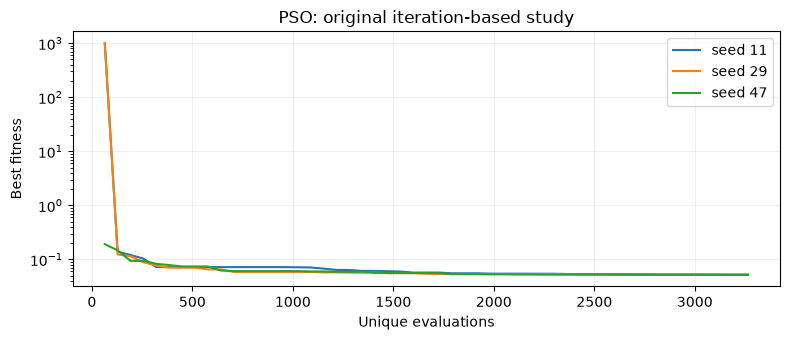

In [5]:
fig,ax=plt.subplots(figsize=(8,3.5))
for record in original_runs:
    history=record['history']
    ax.plot([h['unique_evaluations'] for h in history],[h['best'] for h in history],label=f"seed {record['seed']}")
ax.set(xlabel='Unique evaluations',ylabel='Best fitness',yscale='log',title=f'{METHOD}: original iteration-based study')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
PSO,nominal,30,0.05103350348240746,0.052025843178989103,0.051917325210781524,0.00046374850992765847,30
PSO,robust,30,0.06515258231085962,0.06573683780613984,0.06612486125976656,0.0009329427432311508,30


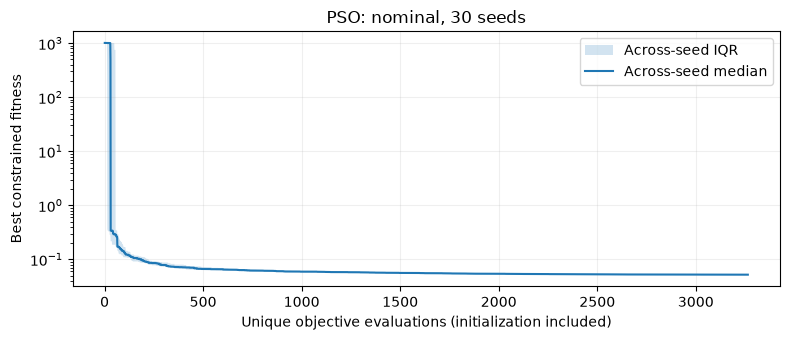

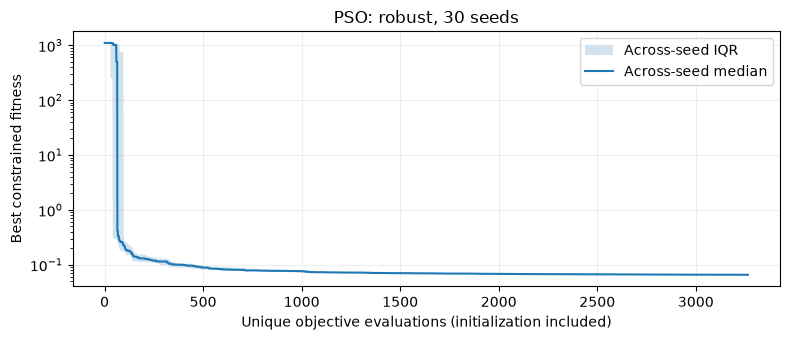

In [6]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [7]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
PSO,nominal,Random single-axis,300,295,297.0,298
PSO,nominal,One-factor boundaries,54,49,50.0,51
PSO,nominal,Combined-axis stress,90,0,0.0,0
PSO,robust,Random single-axis,300,300,300.0,300
PSO,robust,One-factor boundaries,54,53,53.0,53
PSO,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**all work/pid using pso/results/plots/01_step_responses.png**

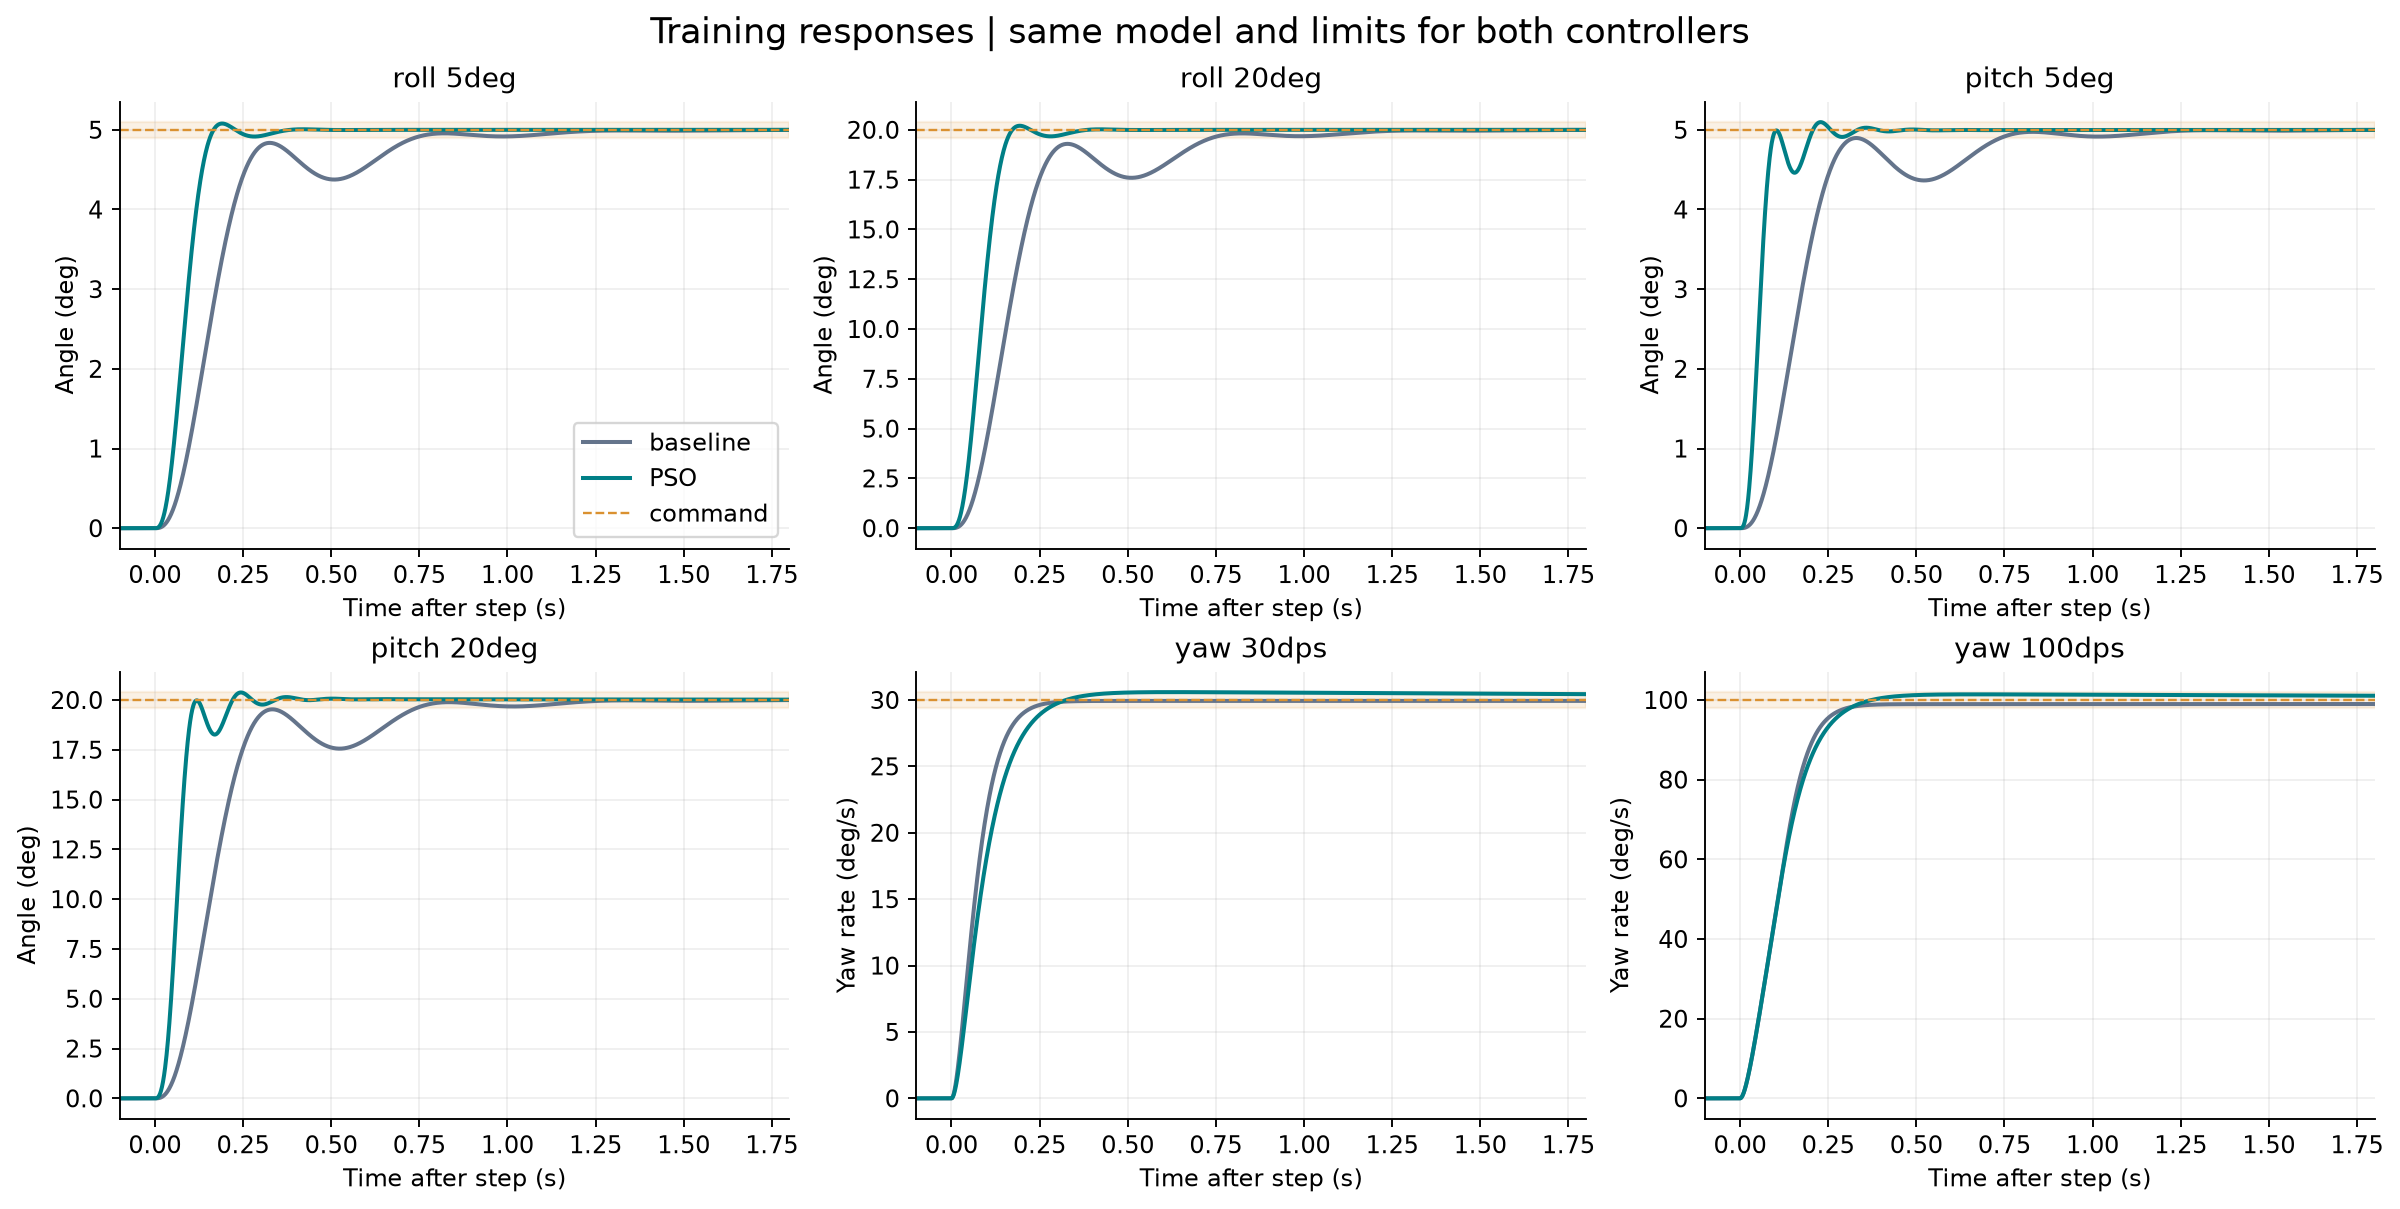

**all work/pid using pso/results/plots/02_pso_iterations.png**

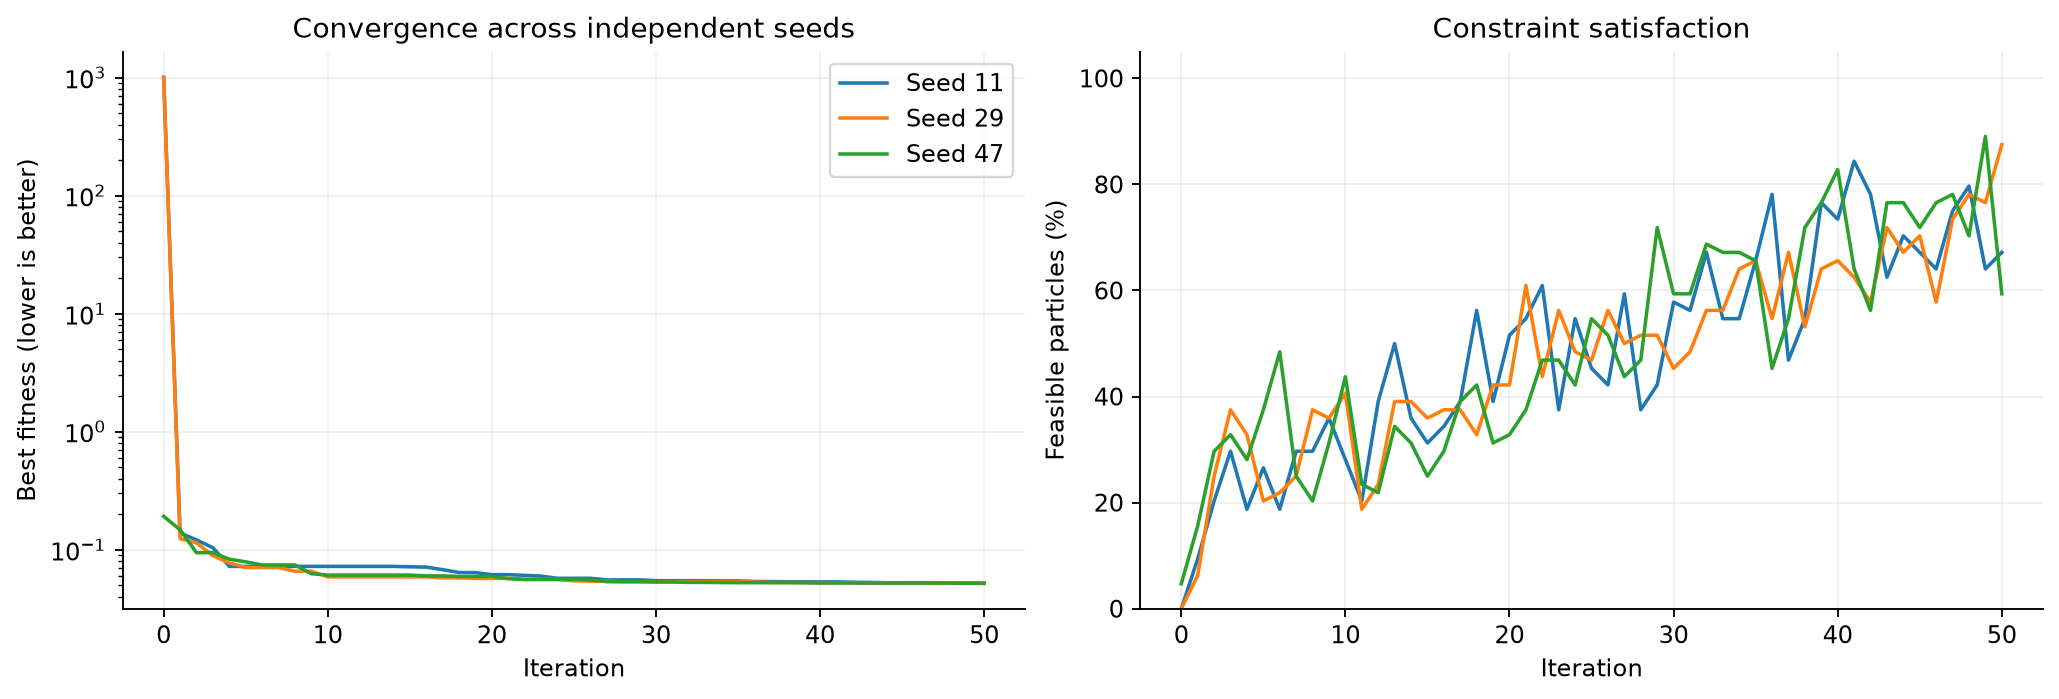

**all work/pid using pso/results/plots/03_coupled_and_saturation.png**

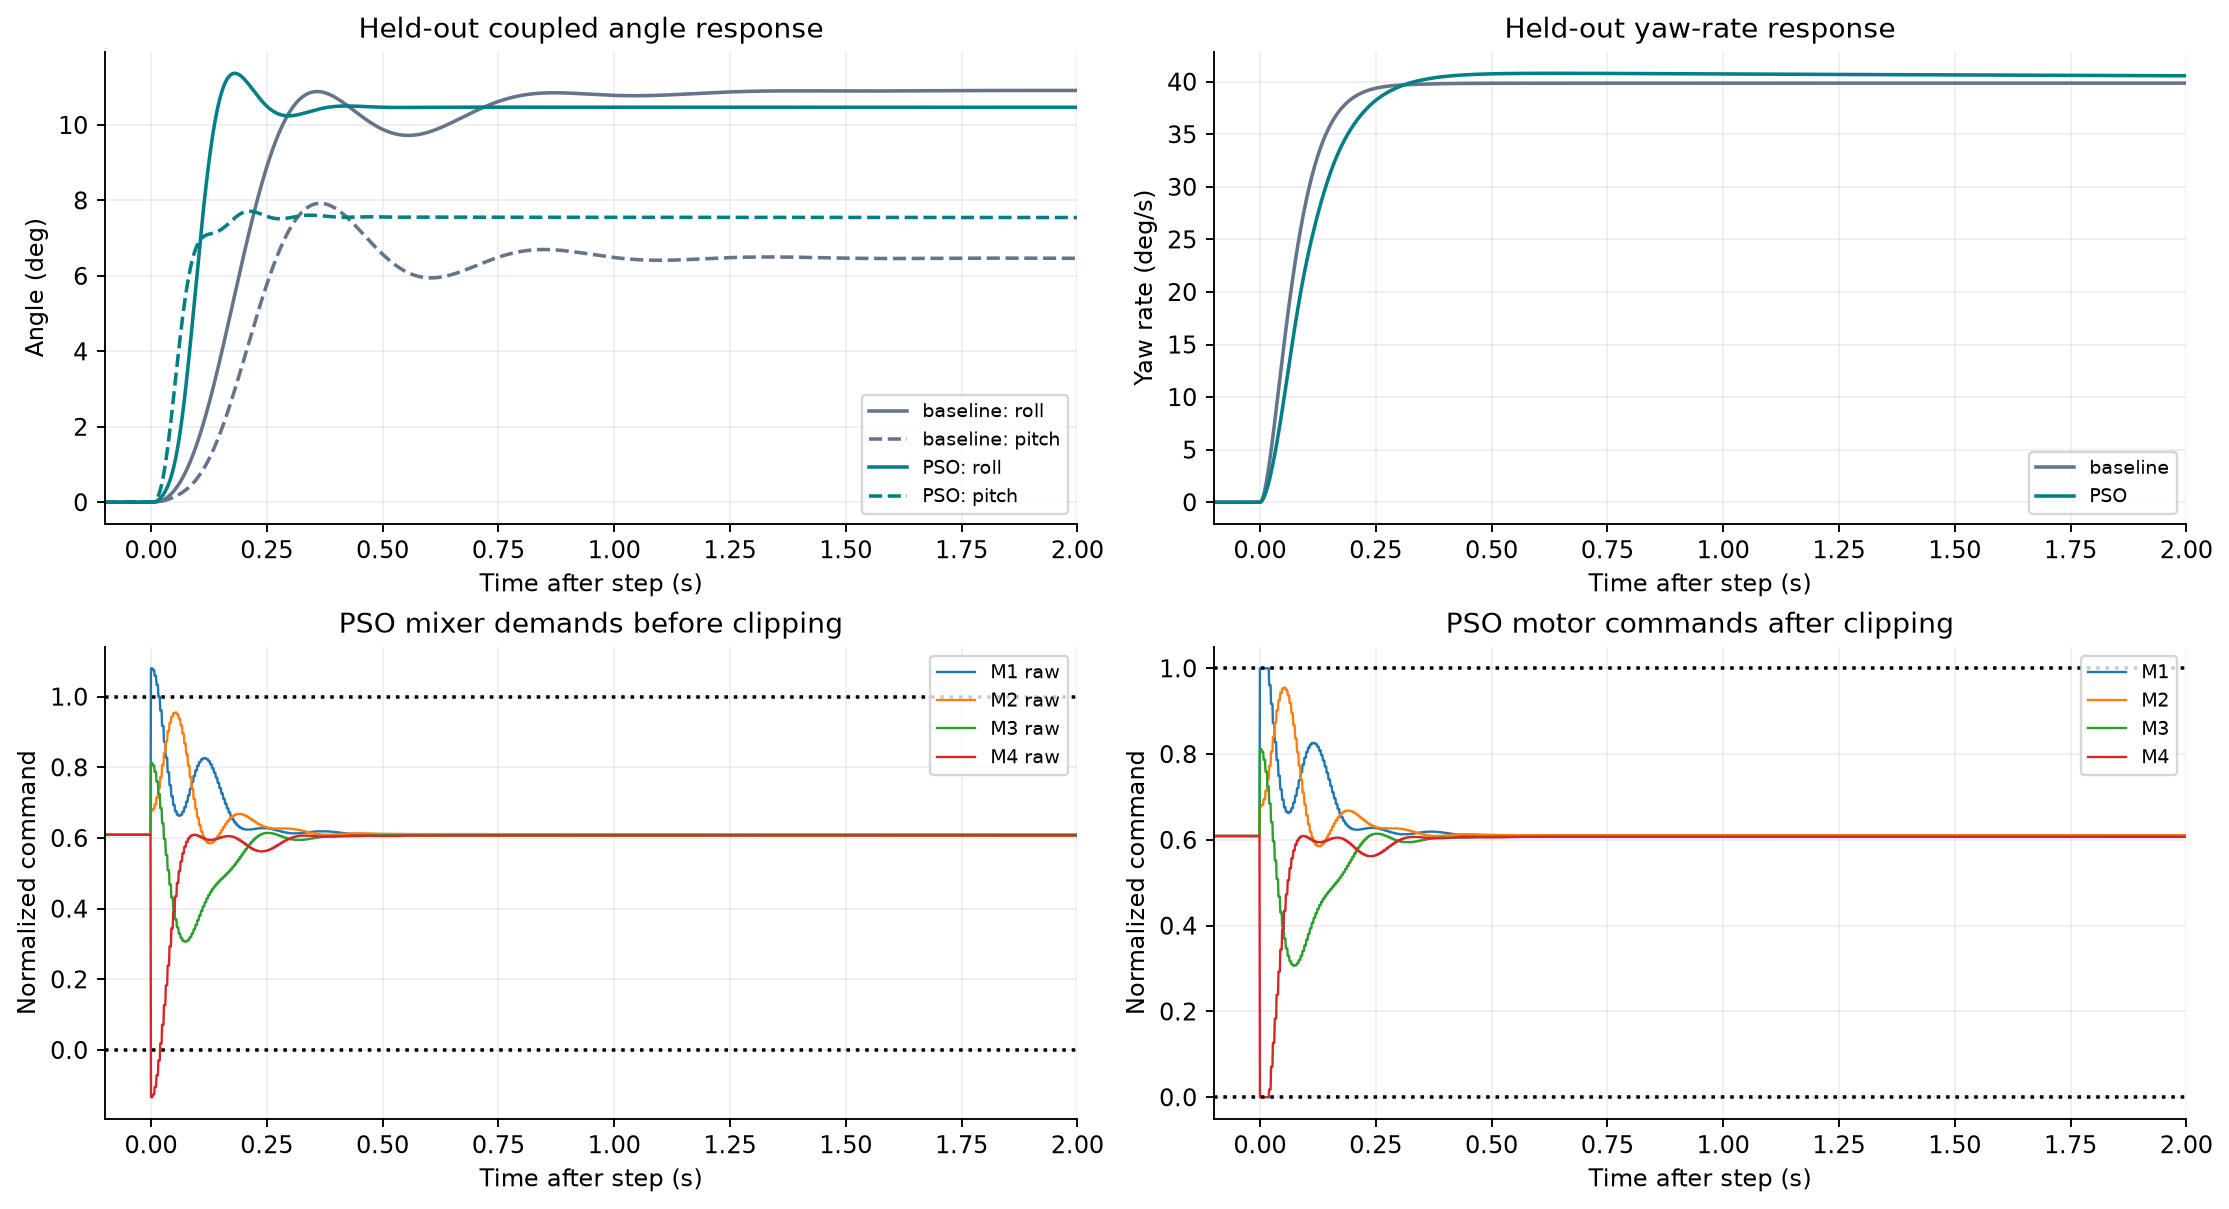

### All saved method figures
- [all work/pid using pso/results/plots/01_step_responses.png](../all%20work/pid%20using%20pso/results/plots/01_step_responses.png)
- [all work/pid using pso/results/plots/02_pso_iterations.png](../all%20work/pid%20using%20pso/results/plots/02_pso_iterations.png)
- [all work/pid using pso/results/plots/03_coupled_and_saturation.png](../all%20work/pid%20using%20pso/results/plots/03_coupled_and_saturation.png)
- [all work/pid using pso/results/plots/04_inner_loops.png](../all%20work/pid%20using%20pso/results/plots/04_inner_loops.png)
- [all work/pid using pso/results/plots/05_robustness.png](../all%20work/pid%20using%20pso/results/plots/05_robustness.png)
- [all work/pid using pso/results/plots/06_gain_sensitivity.png](../all%20work/pid%20using%20pso/results/plots/06_gain_sensitivity.png)
- [all work/pid using pso/results/plots/07_metric_comparison.png](../all%20work/pid%20using%20pso/results/plots/07_metric_comparison.png)
- [all work/pid using pso/results/plots/08_fitness_components.png](../all%20work/pid%20using%20pso/results/plots/08_fitness_components.png)
- [all work/pid using pso/results/plots/09_robust_candidate.png](../all%20work/pid%20using%20pso/results/plots/09_robust_candidate.png)
- [all work/pid using pso/results/plots/10_ga_vs_pso.png](../all%20work/pid%20using%20pso/results/plots/10_ga_vs_pso.png)
- [all work/pid using pso/results/plots/11_ga_vs_pso_convergence.png](../all%20work/pid%20using%20pso/results/plots/11_ga_vs_pso_convergence.png)

In [8]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [9]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from pso import particle_swarm
cfg.update(population=8,swarm_size=8,generations=2,iterations=2,workers=1)
result=particle_swarm(cfg,training_scenarios(),2026,out)
print('Fresh small-search fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../all%20work/pid%20using%20pso/README.md) · [Data checks](../docs/DATA.md)
